# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Datasets

In [1]:
from datasets import load_dataset

# ds = load_dataset("fancyzhx/ag_news") 
ds = load_dataset("stanfordnlp/sst2")
ds

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})

In [2]:
ds_train = ds["train"].to_pandas()
ds_test = ds["test"].to_pandas()

In [3]:
import numpy as np

# let's calculate class frequencies
ds_train["label"].value_counts(normalize=True).to_dict()

{1: 0.5578256544269403, 0: 0.44217434557305973}

# Tokeniser -- sentencepiece PBE

In [4]:
from io import BytesIO
import sentencepiece as spm

model = BytesIO()
spm.SentencePieceTrainer.train(
    sentence_iterator=iter(ds_train["sentence"]),
    model_writer=model,
    model_type="bpe",
    vocab_size=4000
)
tokenizer = spm.SentencePieceProcessor(model_proto=model.getvalue())

I0000 00:00:1794173227.827371 144019143 sentencepiece_trainer.cc:149] Starts training with : 
trainer_spec {
  input_format: 
  model_prefix: 
  model_type: BPE
  vocab_size: 4000
  character_coverage: 0.9995
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 16
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  auto_character_coverage: 0
  vocabulary_output_piece_score: 1
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 0
  bos_id: 1
  eos_id: 2
  pad_id: -1
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece: </s>
  pad_piece: <pad>
  unk_surface:  ⁇ 
}
normalizer_spec {
  name: nmt_nfkc
  add_dummy_prefix: 1
  remove_extra_w

# Encoder -- BoW, bool(BoW), TF-IDF

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import StandardScaler

vectorizer = CountVectorizer(
    analyzer=lambda token_ids: token_ids,
    vocabulary={token_id: token_id for token_id in range(tokenizer.vocab_size())},
)

def encode(sentences, tfidf_transformer=None):
    bow = vectorizer.transform(tokenizer.encode(sentences))

    if tfidf_transformer is None:
        tfidf_transformer = TfidfTransformer().fit(bow)

    representations = {
        "bool(BoW)": bow.astype(bool),
        "BoW": bow,
        "TF-IDF": tfidf_transformer.transform(bow),
    }

    return representations, tfidf_transformer

representations_train, tfidf_transformer = encode(ds_train["sentence"].to_list())
representations_test, _ = encode(ds_test["sentence"].to_list(), tfidf_transformer)

# CatBoost, ReLu MLP, LogisticRegression

use accuracy as the classes are ballanced. we ignore the fact that tokenizer was trained on full cv dataset as for our purposes it does not matter

In [6]:
import numpy as np
import pandas as pd
import torch
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from torch import nn
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

print(f"PyTorch device: {device}")

PyTorch device: mps


In [7]:
def fix_random(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def train_mlp(features, labels, epochs=5, batch_size=256, seed=42):
    fix_random(seed)

    input_dim = features.shape[1]
    num_classes = len(np.unique(labels))

    model = nn.Sequential(
        nn.Linear(input_dim, 128),
        nn.ReLU(),
        nn.Linear(128, num_classes),
    ).to(device)

    optimizer = torch.optim.AdamW(model.parameters())
    loss_fn = nn.CrossEntropyLoss()

    dataset = TensorDataset(
        torch.from_numpy(features.toarray()),
        torch.as_tensor(labels, dtype=torch.long),
    )
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    model.train()
    for _ in range(epochs):
        for inputs, targets in loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            loss = loss_fn(model(inputs), targets)
            loss.backward()

            optimizer.step()

    return model


@torch.inference_mode()
def mlp_probabilities(model, features, batch_size=256):
    model.eval()

    batches = []
    dataset = TensorDataset(torch.from_numpy(features.toarray()))
    loader = DataLoader(dataset, batch_size=batch_size)

    for (inputs,) in loader:
        inputs = inputs.to(device)
        batches.append(model(inputs).softmax(dim=1).cpu().numpy())

    return np.concatenate(batches)

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

labels = ds_train["label"].to_numpy()
results = []


for fold, (train_idx, held_out_idx) in enumerate(
    tqdm(cv.split(labels, labels), total=cv.get_n_splits(), desc="CV folds"), start=1
):
    y_train, y_held_out = labels[train_idx], labels[held_out_idx]

    for name, features in representations_train.items():
        X_train = features[train_idx].astype(np.float32)
        X_held_out = features[held_out_idx].astype(np.float32)

        logistic = LogisticRegression(
            max_iter=1_000
        ).fit(X_train, y_train)
        
        mlp = train_mlp(X_train, y_train)

        catboost = CatBoostClassifier(
            learning_rate=0.15,
            loss_function="Logloss",
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
        ).fit(X_train, y_train)

        predictions = {
            "Logistic regression": logistic.predict(X_held_out),
            "PyTorch MLP": mlp_probabilities(mlp, X_held_out).argmax(axis=1),
            "CatBoost": catboost.predict(X_held_out).ravel(),
        }
        for classifier, predicted in predictions.items():
            results.append({
                "Fold": fold,
                "Representation": name,
                "Classifier": classifier,
                "Accuracy": accuracy_score(y_held_out, predicted),
            })

CV folds:   0%|          | 0/5 [00:00<?, ?it/s]

In [9]:
fold_scores = pd.DataFrame(results)
fold_scores.groupby(["Representation", "Classifier"])["Accuracy"].agg(
    mean="mean", std="std"
).round(4)

mean     std
Representation Classifier                         
BoW            CatBoost             0.8896  0.0016
               Logistic regression  0.8686  0.0013
               PyTorch MLP          0.9047  0.0023
TF-IDF         CatBoost             0.8898  0.0011
               Logistic regression  0.8622  0.0022
               PyTorch MLP          0.8783  0.0024
bool(BoW)      CatBoost             0.8894  0.0021
               Logistic regression  0.8681  0.0014
               PyTorch MLP          0.9039  0.0021

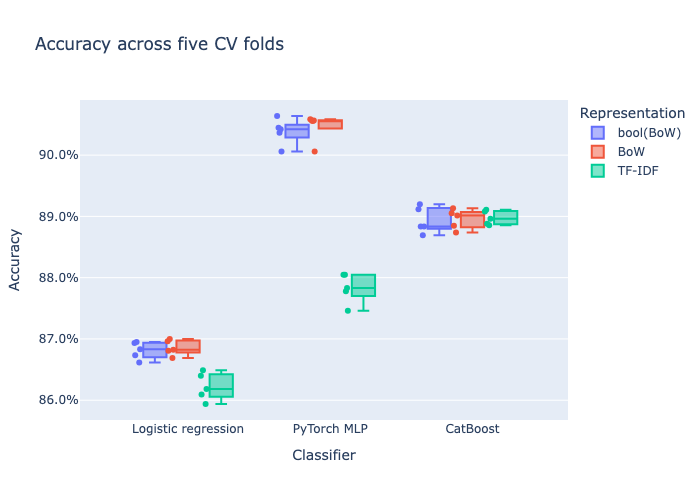

In [22]:
import plotly.express as px

fig = px.box(
    fold_scores,
    x="Classifier",
    y="Accuracy",
    color="Representation",
    points="all",
    title="Accuracy across five CV folds"
)
fig.update_yaxes(tickformat=".1%")
fig.show(renderer="png")

# Bayesian comparison with a ROPE

The nine systems (3 representations x 3 classifiers) have similar mean accuracies, and some gaps are tiny, so a table of means cannot say which differences matter. We therefore compare systems with the **Bayesian correlated t-test** of Benavoli et al. (2017), via `baycomp` (the same method as `BenavoliCorrelatedT` in the tutorial's `analysis.py`).

* The five fold accuracies of two systems are **paired** (same folds) and **not independent** (the training sets of different folds overlap). The test applies the Nadeau-Bengio variance correction for this.
* For two systems A and B it gives a Student-t **posterior over mu = mean accuracy difference (B - A)**.
* The **ROPE** (region of practical equivalence) is the interval (-r, +r) of differences we consider too small to matter. The posterior splits into three regions: **A better** (mu < -r), **practically equivalent** (|mu| < r) and **B better** (mu > r). We only call a region when its posterior probability is at least **95%**; otherwise the comparison is **undecided**.

**Choice of ROPE: r = 0.5 percentage points of accuracy (0.005).**
1. Each held-out fold has about 13,500 sentences, so the binomial standard error of one fold's accuracy at ~89% is about 0.27 pp. A gap of 0.5 pp is roughly two standard errors of pure sampling noise on a single fold.
2. 0.5 pp is about 5 sentences per 1,000. We would not switch to a slower or more complex system for that, so treat it as practically irrelevant.
3. Because this is a judgement call, we also report a **sensitivity analysis** with r = 0.25 pp and r = 1 pp.

In [11]:
import itertools
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from baycomp import CorrelatedTTest  # pip install baycomp

ROPE = 0.005       # +/- 0.5 percentage points of accuracy
THRESHOLD = 0.95   # posterior probability needed to call a region
RUNS = 1           # we ran a single 5-fold cross-validation

REPS = ["bool(BoW)", "BoW", "TF-IDF"]
CLFS = ["Logistic regression", "PyTorch MLP", "CatBoost"]

# rows = folds, columns = (representation, classifier): scores are paired by fold
scores = fold_scores.pivot_table(index="Fold", columns=["Representation", "Classifier"], values="Accuracy")


def posterior(a, b, runs=RUNS):
    """Student-t posterior of mu = mean(b - a), with the Nadeau-Bengio variance correction."""
    mean, var, df = CorrelatedTTest.compute_statistics(np.asarray(a), np.asarray(b), runs)
    return st.t(df, loc=mean, scale=np.sqrt(var))


def region_probs(post, rope=ROPE):
    """P(A better), P(practically equivalent), P(B better)."""
    p_a = post.cdf(-rope)
    p_tie = post.cdf(rope) - post.cdf(-rope)
    p_b = 1 - post.cdf(rope)
    return p_a, p_tie, p_b


def decide(p_a, p_tie, p_b, threshold=THRESHOLD):
    """Name the region that reaches the threshold, else 'undecided'."""
    p, label = max(zip((p_a, p_tie, p_b), ("A better", "equivalent", "B better")))
    return label if p >= threshold else "undecided"


def name(system):
    return f"{system[1]} ({system[0]})"


def compare(pairs, rope=ROPE):
    """One row per (A, B) pair of systems."""
    rows = []
    for A, B in pairs:
        post = posterior(scores[A], scores[B])
        p_a, p_tie, p_b = region_probs(post, rope)
        lo, hi = post.interval(0.95)
        rows.append({
            "A": name(A), "B": name(B),
            "mean diff B-A (pp)": 100 * post.mean(),
            "95% interval (pp)": f"[{100 * lo:+.2f}, {100 * hi:+.2f}]",
            "P(A better)": p_a, "P(equivalent)": p_tie, "P(B better)": p_b,
            "decision": decide(p_a, p_tie, p_b),
        })
    return pd.DataFrame(rows).round(3)

## 1. Does the representation matter? (same classifier, different representation)

In [12]:
rep_pairs = [((a, clf), (b, clf)) for clf in CLFS for a, b in itertools.combinations(REPS, 2)]
compare(rep_pairs)

,A,B,mean diff B-A (pp),95% interval (pp),P(A better),P(equivalent),P(B better),decision
0,Logistic regression (bool(BoW)),Logistic regression (BoW),0.045,"[-0.04, +0.13]",0.000,1.000,0.000,equivalent
1,Logistic regression (bool(BoW)),Logistic regression (TF-IDF),-0.591,"[-0.84, -0.34]",0.815,0.185,0.000,undecided
2,Logistic regression (BoW),Logistic regression (TF-IDF),-0.635,"[-0.90, -0.37]",0.883,0.117,0.000,undecided
3,PyTorch MLP (bool(BoW)),PyTorch MLP (BoW),0.080,"[-0.14, +0.30]",0.001,0.996,0.003,equivalent
4,PyTorch MLP (bool(BoW)),PyTorch MLP (TF-IDF),-2.552,"[-2.71, -2.39]",1.000,0.000,0.000,A better
5,PyTorch MLP (BoW),PyTorch MLP (TF-IDF),-2.633,"[-2.88, -2.39]",1.000,0.000,0.000,A better
6,CatBoost (bool(BoW)),CatBoost (BoW),0.021,"[-0.36, +0.40]",0.010,0.978,0.013,equivalent
7,CatBoost (bool(BoW)),CatBoost (TF-IDF),0.042,"[-0.45, +0.54]",0.019,0.949,0.031,undecided
8,CatBoost (BoW),CatBoost (TF-IDF),0.021,"[-0.23, +0.27]",0.002,0.995,0.003,equivalent


## 2. Does the classifier matter? (same representation, different classifier)

In [13]:
clf_pairs = [((rep, a), (rep, b)) for rep in REPS for a, b in itertools.combinations(CLFS, 2)]
compare(clf_pairs)

,A,B,mean diff B-A (pp),95% interval (pp),P(A better),P(equivalent),P(B better),decision
0,Logistic regression (bool(BoW)),PyTorch MLP (bool(BoW)),3.574,"[+3.32, +3.83]",0.000,0.000,1.000,B better
1,Logistic regression (bool(BoW)),CatBoost (bool(BoW)),2.123,"[+1.58, +2.67]",0.000,0.000,0.999,B better
2,PyTorch MLP (bool(BoW)),CatBoost (bool(BoW)),-1.451,"[-2.09, -0.81]",0.993,0.007,0.001,A better
3,Logistic regression (BoW),PyTorch MLP (BoW),3.610,"[+3.32, +3.90]",0.000,0.000,1.000,B better
4,Logistic regression (BoW),CatBoost (BoW),2.100,"[+1.70, +2.50]",0.000,0.000,1.000,B better
5,PyTorch MLP (BoW),CatBoost (BoW),-1.510,"[-2.08, -0.94]",0.996,0.004,0.000,A better
6,Logistic regression (TF-IDF),PyTorch MLP (TF-IDF),1.613,"[+1.14, +2.09]",0.000,0.001,0.999,B better
7,Logistic regression (TF-IDF),CatBoost (TF-IDF),2.756,"[+2.43, +3.08]",0.000,0.000,1.000,B better
8,PyTorch MLP (TF-IDF),CatBoost (TF-IDF),1.143,"[+0.83, +1.45]",0.000,0.002,0.998,B better


## 3. Which system is best? (the best system by mean accuracy against all the others)

In [14]:
means = scores.mean()
best = means.idxmax()
print(f"Best system by mean CV accuracy: {name(best)} = {means[best]:.4f}")

best_vs_all = compare([(best, other) for other in scores.columns if other != best])
best_vs_all.sort_values("mean diff B-A (pp)", ascending=False).reset_index(drop=True)

Best system by mean CV accuracy: PyTorch MLP (BoW) = 0.9047


,A,B,mean diff B-A (pp),95% interval (pp),P(A better),P(equivalent),P(B better),decision
0,PyTorch MLP (BoW),PyTorch MLP (bool(BoW)),-0.080,"[-0.30, +0.14]",0.003,0.996,0.001,equivalent
1,PyTorch MLP (BoW),CatBoost (TF-IDF),-1.489,"[-1.87, -1.11]",0.999,0.001,0.000,A better
2,PyTorch MLP (BoW),CatBoost (BoW),-1.510,"[-2.08, -0.94]",0.996,0.004,0.000,A better
3,PyTorch MLP (BoW),CatBoost (bool(BoW)),-1.531,"[-2.28, -0.78]",0.990,0.009,0.001,A better
4,PyTorch MLP (BoW),PyTorch MLP (TF-IDF),-2.633,"[-2.88, -2.39]",1.000,0.000,0.000,A better
5,PyTorch MLP (BoW),Logistic regression (BoW),-3.610,"[-3.90, -3.32]",1.000,0.000,0.000,A better
6,PyTorch MLP (BoW),Logistic regression (bool(BoW)),-3.654,"[-3.92, -3.39]",1.000,0.000,0.000,A better
7,PyTorch MLP (BoW),Logistic regression (TF-IDF),-4.245,"[-4.73, -3.76]",1.000,0.000,0.000,A better


## 4. Sensitivity to the ROPE size

Do the conclusions depend on our choice of r? Each cell shows the decision and the probability of the leading region.

In [15]:
headline = {
    "A=MLP, B=CatBoost (BoW)":          (("BoW", "PyTorch MLP"), ("BoW", "CatBoost")),
    "A=LogReg, B=CatBoost (BoW)":       (("BoW", "Logistic regression"), ("BoW", "CatBoost")),
    "A=MLP, B=CatBoost (TF-IDF)":       (("TF-IDF", "PyTorch MLP"), ("TF-IDF", "CatBoost")),
    "A=bool(BoW), B=BoW (MLP)":         (("bool(BoW)", "PyTorch MLP"), ("BoW", "PyTorch MLP")),
    "A=BoW, B=TF-IDF (LogReg)":         (("BoW", "Logistic regression"), ("TF-IDF", "Logistic regression")),
    "A=BoW, B=TF-IDF (MLP)":            (("BoW", "PyTorch MLP"), ("TF-IDF", "PyTorch MLP")),
    "A=BoW, B=TF-IDF (CatBoost)":       (("BoW", "CatBoost"), ("TF-IDF", "CatBoost")),
}

sensitivity = {}
for label, (A, B) in headline.items():
    post = posterior(scores[A], scores[B])
    row = {}
    for r in (0.0025, 0.005, 0.01):
        probs = region_probs(post, r)
        row[f"ROPE {100 * r:.2f} pp"] = f"{decide(*probs)} ({max(probs):.2f})"
    sensitivity[label] = row

pd.DataFrame(sensitivity).T

,ROPE 0.25 pp,ROPE 0.50 pp,ROPE 1.00 pp
"A=MLP, B=CatBoost (BoW)",A better (1.00),A better (1.00),A better (0.97)
"A=LogReg, B=CatBoost (BoW)",B better (1.00),B better (1.00),B better (1.00)
"A=MLP, B=CatBoost (TF-IDF)",B better (1.00),B better (1.00),undecided (0.87)
"A=bool(BoW), B=BoW (MLP)",undecided (0.94),equivalent (1.00),equivalent (1.00)
"A=BoW, B=TF-IDF (LogReg)",A better (0.99),undecided (0.88),equivalent (0.99)
"A=BoW, B=TF-IDF (MLP)",A better (1.00),A better (1.00),A better (1.00)
"A=BoW, B=TF-IDF (CatBoost)",undecided (0.95),equivalent (0.99),equivalent (1.00)


## 5. Posteriors for two headline comparisons

Left: a clear difference (the MLP beats CatBoost on BoW). Right: a practical tie (BoW vs bool(BoW) for the MLP).

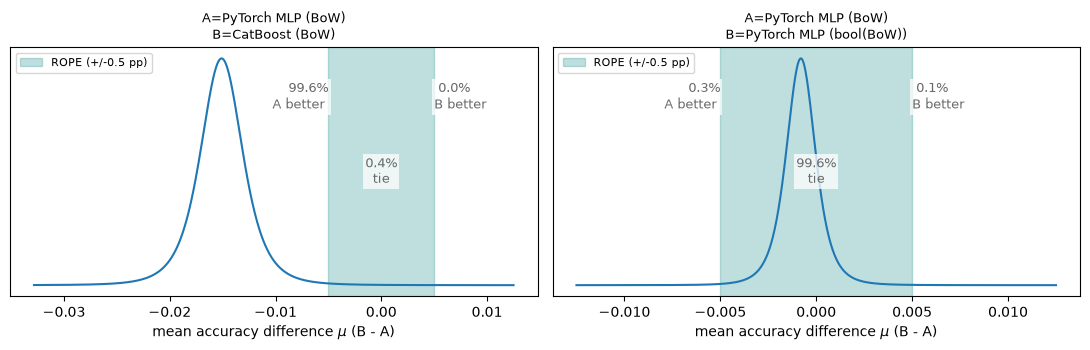

In [16]:
def plot_posterior(ax, A, B, rope=ROPE):
    post = posterior(scores[A], scores[B])
    p_a, p_tie, p_b = region_probs(post, rope)
    lo, hi = post.interval(0.999)
    x = np.linspace(min(lo, -2.5 * rope), max(hi, 2.5 * rope), 1000)
    ax.plot(x, post.pdf(x))
    ax.axvspan(-rope, rope, color="teal", alpha=0.25, label=f"ROPE (+/-{100 * rope:.1f} pp)")
    ax.set_xlabel(r"mean accuracy difference $\mu$ (B - A)")
    ax.set_yticks([])
    ax.set_title(f"A={name(A)}\nB={name(B)}", fontsize=9)
    tr = ax.get_xaxis_transform()
    box = dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1.5)
    ax.text(-rope, 0.8, f"{100 * p_a:.1f}%\nA better ", ha="right", va="center", transform=tr, fontsize=9, color="dimgray", bbox=box)
    ax.text(0, 0.5, f"{100 * p_tie:.1f}%\ntie", ha="center", va="center", transform=tr, fontsize=9, color="dimgray", bbox=box)
    ax.text(rope, 0.8, f" {100 * p_b:.1f}%\nB better", ha="left", va="center", transform=tr, fontsize=9, color="dimgray", bbox=box)
    ax.legend(loc="upper left", fontsize=8)


fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
plot_posterior(axs[0], ("BoW", "PyTorch MLP"), ("BoW", "CatBoost"))
plot_posterior(axs[1], ("BoW", "PyTorch MLP"), ("bool(BoW)", "PyTorch MLP"))
fig.tight_layout()
plt.show()

## 6. Conclusions from the Bayesian analysis

Results below are from the run saved in this notebook (ROPE = 0.5 pp, 95% decision threshold).

**Best system.** The MLP on BoW (90.5% mean CV accuracy) is the best system, and the MLP on bool(BoW) is practically equivalent to it (P(equivalent) = 0.996), so either is a fine choice; bool(BoW) is the simpler one. Both beat every other system with at least 99% posterior probability. The closest competitor is CatBoost, about 1.5 pp behind.

**Classifier.** On BoW and bool(BoW) the ranking is MLP > CatBoost > logistic regression, and each step is decided with at least 99% probability (MLP over CatBoost by about 1.5 pp, CatBoost over logistic regression by about 2.1 pp). The linear model lacks capacity for feature interactions (e.g. negation) that the MLP and the trees can use.

**Representation.**
* bool(BoW) and BoW are practically equivalent for every classifier (P(equivalent) of at least 0.98 for the MLP, logistic regression and CatBoost at r = 0.5 pp). For short sentences, repeated tokens are rare, so counts add almost nothing over presence.
* TF-IDF never helps. It clearly hurts the MLP (about 2.6 pp), and its effect on logistic regression is small (about 0.6 pp worse) and undecided at r = 0.5 pp. CatBoost is unaffected.
* With TF-IDF the classifier ranking changes: CatBoost beats the MLP by about 1.1 pp (P = 0.998), only because the MLP gets worse. This particular conclusion is ROPE-dependent: with r = 1 pp it becomes undecided (see section 4).
* Possible explanations (hypotheses, we did not test them): TF-IDF with L2-normalised rows yields very small feature values, so the MLP, trained for a fixed 5 epochs with default AdamW settings, may be under-trained; decision trees are largely insensitive to feature scaling.

**Caveats.**
* We have one run of 5-fold CV, so each test uses only five paired differences (4 degrees of freedom, heavy tails). Repeating CV with several seeds (`runs` > 1) would tighten the posteriors.
* The training set contains phrases cut from the same sentences, so phrases from one sentence can fall in different folds. This probably inflates absolute accuracies; the comparisons between systems are likely less affected, but not guaranteed to be.
* The ROPE size and the 95% threshold are judgement calls (see the sensitivity table). We ran 26 comparisons without any multiplicity adjustment, so read them as a pattern rather than as independent tests, and note that "best" was picked from the same data. A final unbiased estimate needs a split that was not used for selection (e.g. the SST-2 validation set).
* Hyperparameters of all three classifiers were left at (near-)default values, so the ranking is for these configurations, not for each model family at its best.